<a href="https://colab.research.google.com/github/fahimshahariar1/transaction-fraud-detector/blob/main/Transaction_Fraud_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transaction Fraud Detector
In today's digital world transation fraud is a regular thing. In this notebook we will try to use AI ML to detect the fraud and also would try to prevent it

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
creditCardUrl = "/content/drive/MyDrive/AI ML/creditcard.csv"
creditCard_df = pd.read_csv(creditCardUrl)
creditCard_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
creditCard_df.shape

(284807, 31)

In [4]:
creditCard_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 1. Explaratory Data Analysis

Before training a fraud detection model, we investigate data quality,
class imbalance, transaction characteristics, and potential preprocessing
requirements.

In [16]:
creditCard_df.isnull().sum().sum()

np.int64(0)

In [7]:
creditCard_df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [19]:
print("Duplicate Rows: ",creditCard_df.duplicated().sum())

Duplicate Rows:  1081


In [20]:
creditCard_df[creditCard_df.duplicated(keep=False)].head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [9]:
creditCard_df["Class"].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


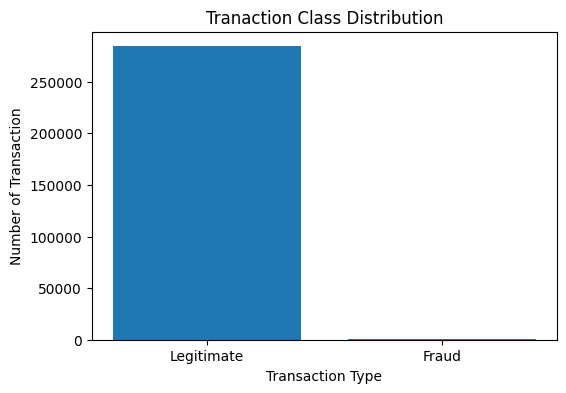

In [10]:
class_counts = creditCard_df["Class"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(["Legitimate", "Fraud"], class_counts.values)

plt.title("Tranaction Class Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transaction")

plt.show()

In [14]:
fraud_count = creditCard_df["Class"].sum()
total_transaction = len(creditCard_df)

fraud_percentage = fraud_count / total_transaction * 100

print(f"Total number of transaction: {total_transaction}")
print(f"Number of fraud transaction: {fraud_count}")
print(f"Percentage of fraud transaction: {fraud_percentage:.2f}%")

Total number of transaction: 284807
Number of fraud transaction: 492
Percentage of fraud transaction: 0.17%


In [11]:
creditCard_df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [13]:
legitimate = creditCard_df[creditCard_df["Class"] == 0]
fraud = creditCard_df[creditCard_df["Class"] == 1]

print("Legitimate Transaction Amount:")
print(legitimate["Amount"].describe())

print("\nFraud Transaction Amount:")
print(fraud["Amount"].describe())

Legitimate Transaction Amount:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud Transaction Amount:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


In [22]:
creditCard_df["TimeHours"] = creditCard_df["Time"] / 3600
creditCard_df.groupby("Class")["TimeHours"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,26.343945,13.190004,0.000000,15.063889,23.530833,38.703611,47.997778
1,492.0,22.429669,13.287601,0.112778,11.455972,20.991250,35.689722,47.318889


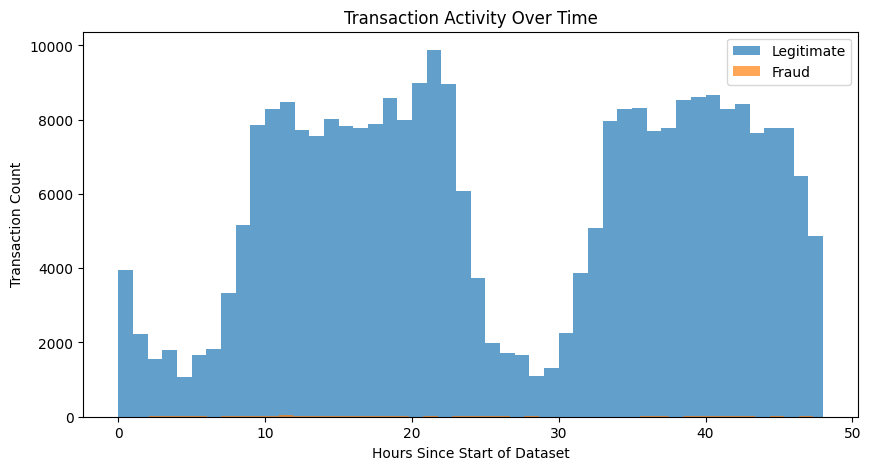

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(
    legitimate["Time"] / 3600,
    bins=48,
    alpha=0.7,
    label="Legitimate"
)

plt.hist(
    fraud["Time"] / 3600,
    bins=48,
    alpha=0.7,
    label="Fraud"
)

plt.xlabel("Hours Since Start of Dataset")
plt.ylabel("Transaction Count")
plt.title("Transaction Activity Over Time")
plt.legend()

plt.show()

## Initial Observations